04 temporal model: how should 300 frames become one answer?

ScoNet-MT treats a video as a **set** of frames: every frame goes through ResNet9 alone, and then it takes the **maximum over all frames** for every feature cell (`TP = max`). so the order of the frames doesn't matter, and one frame can decide a cell alone. but a Scoliosis1K video is not one view, the child walks towards the camera, turns, walks away, etc. (old notebook 01 on views). TG-MILNet's main idea is to split the frames into **bags** (gait phases / views) and let attention decide which bags matter.

in part A i look at what max pooling does in my trained model: in step 1 if it's really order-free, in step 2 which frames "win" the max in my ScoNet-MT@16k, and in step 3 if the winning frames follow the view (silhouette width). in part B i try learned pooling: in step 4 attention pooling explained by hand, and in step 5 three temporal heads in a mini training (max, attention over frames, attention over view bags).

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE)

device: cuda


part A: what max pooling does in my trained model

step 1: is it really order-free?

i load my full ScoNet-MT@16k (official run of checkpoint_1, reimplemented in `tools/common.py`, and it gives exactly the saved logits) and run one test child twice, with the frames in order and with the frames shuffled. with a max over frames the answer must be identical.

In [2]:
model16 = load_sconet_16k()
_, true_all, subj_all = load_saved_logits('official', 16000)
child = subj_all[0]
seq = sil_transform(load_seq(child))
perm = np.random.default_rng(0).permutation(len(seq))
with torch.no_grad():
    z_order = model16(torch.tensor(seq).unsqueeze(0).to(DEVICE))['logits']
    z_shuffle = model16(torch.tensor(seq[perm]).unsqueeze(0).to(DEVICE))['logits']
print('child', child, '| frames', seq.shape, '| max |difference| ordered vs shuffled:',
      (z_order - z_shuffle).abs().max().item())

child 01466 | frames (300, 64, 44) | max |difference| ordered vs shuffled: 0.0


the difference between ordered and shuffled frames is exactly **0.0**. so the order of the 300 frames has no influence at all on ScoNet-MT's answer: the model sees the video as a bag of separate pictures, and "walking" (how a frame follows the previous one) is invisible to it.

step 2: which frames win the max?

the feature map after ResNet9 is `[frames, 512, 16, 11]`, and max pooling keeps for each of the `512 x 16 x 11 = 90,112` cells the value of **one** frame. so i count for every frame how many cells it wins (`argmax` over frames). cells that have the same value in every frame (mostly 0 after the ReLU) have no real winner, and `argmax` would return frame 0 for them, which in my first try made frame 0 look like it wins 6-10% of the cells. so i only count the cells where the frames differ. if the wins are spread evenly, every frame gets 1/300 = 0.33% of the cells, and if a few frames win most cells, the decision depends on very few frames.

i do this for 60 test children (20 per class), and per frame i also measure the silhouette **width** and **height** (bounding box of the white pixels in the 64 x 64 image), as a simple stand-in for the view (front / back = wide shoulders, side = narrow). the pkl frames are already scaled so that the body fills the full height, so the height is almost always 64 and only the width really changes.

In [3]:
def box_size(seq_uint8):
    """width and height of the white area of every frame (in pixels)"""
    widths, heights = [], []
    for frame in seq_uint8:
        cols = np.where(frame.max(0) > 0)[0]
        rows = np.where(frame.max(1) > 0)[0]
        widths.append(cols[-1] - cols[0] + 1 if len(cols) else 0)
        heights.append(rows[-1] - rows[0] + 1 if len(rows) else 0)
    return np.array(widths), np.array(heights)


@torch.no_grad()
def frame_wins(model, seq_float):
    f = encode_frames(model.backbone, torch.tensor(seq_float).unsqueeze(0).to(DEVICE))[0]   # [s, 512, 16, 11]
    f = f.flatten(1)                                                                         # [s, cells]
    # cells where all frames have the same value (e.g. 0 after the ReLU) have no real winner:
    # argmax would just return frame 0 there, so I leave them out
    real = (f.max(0)[0] > f.min(0)[0])
    winner = f[:, real].argmax(0).cpu().numpy()                                              # frame index per cell
    return np.bincount(winner, minlength=len(seq_float)) / winner.size, real.float().mean().item()


rng = np.random.default_rng(0)
chosen = [s for c in range(3) for s in rng.choice(subj_all[true_all == c], 20, replace=False)]
win_share, widths, heights, labels_c, real_share = [], [], [], [], []
for s in chosen:
    raw = load_seq(s)
    share, real = frame_wins(model16, sil_transform(raw))
    win_share.append(share)
    real_share.append(real)
    w, h = box_size(raw)
    widths.append(w)
    heights.append(h)
    labels_c.append(subject_class(s))
win_share, widths, heights = np.array(win_share), np.array(widths), np.array(heights)

top10 = np.sort(win_share, 1)[:, ::-1][:, :30].sum(1)        # share won by the best 10% (30) frames
print('frames per child:', win_share.shape[1])
print('cells where the frames differ (the rest is the same in every frame, mostly 0): mean', round(100 * np.mean(real_share), 1), '%')
print('share of cells won by the top 10% frames: mean', round(100 * top10.mean(), 1), '% | min',
      round(100 * top10.min(), 1), '% | max', round(100 * top10.max(), 1), '%  (even spread = 10%)')
print('frames that win NO cell at all: mean', round((win_share == 0).sum(1).mean(), 1), 'of 300')

frames per child: 300
cells where the frames differ (the rest is the same in every frame, mostly 0): mean 92.8 %
share of cells won by the top 10% frames: mean 27.8 % | min 23.2 % | max 34.4 %  (even spread = 10%)
frames that win NO cell at all: mean 0.0 of 300


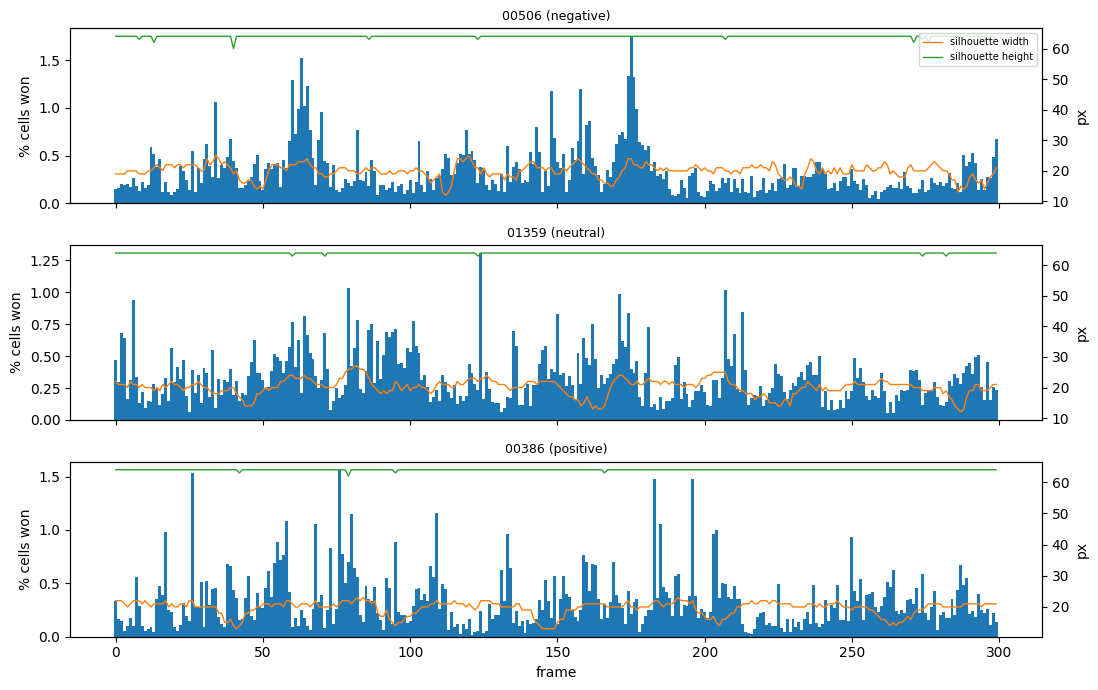

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, i in zip(ax, [0, 20, 40]):
    a.bar(range(300), 100 * win_share[i], color='tab:blue', width=1.0, label='% of cells won')
    a2 = a.twinx()
    a2.plot(widths[i], color='tab:orange', lw=1, label='silhouette width')
    a2.plot(heights[i], color='tab:green', lw=1, label='silhouette height')
    a.set_title(f'{chosen[i]} ({labels_c[i]})', fontsize=9)
    a.set_ylabel('% cells won')
    a2.set_ylabel('px')
    if i == 0:
        a2.legend(fontsize=7, loc='upper right')
ax[-1].set_xlabel('frame')
save_and_show(fig, '02_frame_wins.png')

in 92.8% of the cells the frames really differ, and the other 7.2% are the same in every frame (mostly 0 after the ReLU), so i leave them out. **the best 10% of the frames (30 frames) win 27.8% of the cells** (between 23 and 34% per child). an even spread would be 10%, so the max listens about 3 times more to some frames than to others. still, every frame wins at least a few cells, so no frame is completely ignored.

in the 3 examples the winning frames come in **clusters** (e.g. the negative child around frames 60-65 and 170-178). some clusters sit where the width changes quickly (turning) and some don't, so by eye there is no simple rule. the width (orange) dips every ~60 frames down to ~13-15 px, and those are the turns, where the child is seen from the side.

step 3: do the winning frames follow the view?

for every child i compute the Spearman correlation between the win share of a frame and its width (`scipy.stats.spearmanr`, a library function). so: are the winning frames the wide ones (front / back) or the narrow ones (side / turning)?

In [5]:
from scipy.stats import spearmanr

rho_w = np.array([spearmanr(win_share[i], widths[i])[0] for i in range(len(chosen))])
print('Spearman(win share, width) : mean', rho_w.mean().round(2), '| children with rho > 0:', (rho_w > 0).sum(), 'of', len(rho_w))
print('frames with height != 64:', round(100 * (heights != 64).mean(), 1), '% -> height is (almost) constant, no correlation needed')

# split every child's frames in 4 groups by width (narrow ... wide) and sum the wins per group
groups = np.zeros((len(chosen), 4))
for i in range(len(chosen)):
    order = np.argsort(widths[i], kind='stable')
    for g in range(4):
        groups[i, g] = win_share[i, order[g * 75:(g + 1) * 75]].sum()
print()
print('share of cells won by each width quarter (equal would be 25% each):')
for g, name in enumerate(['narrowest 25%', 'narrow', 'wide', 'widest 25%']):
    print(f'  {name:14s} | all {100 * groups[:, g].mean():5.1f}% | ' +
          ' | '.join(f'{LABEL_NAMES[c][:3]} {100 * groups[np.array(labels_c) == LABEL_NAMES[c], g].mean():5.1f}%' for c in range(3)))

Spearman(win share, width) : mean 0.04 | children with rho > 0: 34 of 60
frames with height != 64: 2.0 % -> height is (almost) constant, no correlation needed

share of cells won by each width quarter (equal would be 25% each):
  narrowest 25%  | all  26.9% | neg  26.6% | neu  28.0% | pos  26.2%
  narrow         | all  21.3% | neg  21.6% | neu  20.7% | pos  21.7%
  wide           | all  21.5% | neg  21.7% | neu  21.4% | pos  21.4%
  widest 25%     | all  30.3% | neg  30.2% | neu  29.9% | pos  30.7%


**over single frames there is no relation between winning and width: Spearman 0.04 on average**, positive for 34 of 60 children (that's coin-flip level). **but over the width quarters the extremes win more**: the widest 25% of the frames win 30.3% of the cells and the narrowest 25% win 26.9%, while the middle quarters only win ~21%. so the max likes the *unusual* frames, the widest (front / back, arms out) and the narrowest (side view while turning). that's what a max does, it collects the extremes of every feature.

**this is the same for all 3 classes** (negative 30.2 / neutral 29.9 / positive 30.7% for the widest quarter), so which frames win doesn't depend on the class. the height is 64 in 98% of the frames (the pkl frames are scaled to full height), so only the width tells something about the view.

part B: learned temporal pooling

step 4: attention pooling, by hand

instead of a max, **attention pooling** gives every frame `t` a score `e_t`, turns the scores into weights with a softmax, and takes the weighted mean of the frame features `h_t`:

`alpha_t = exp(e_t) / sum_j exp(e_j)`, `pooled = sum_t alpha_t * h_t`

the score comes from a small network that looks at the frame itself. i use the **gated attention** of Ilse et al. 2018 ("Attention-based Deep Multiple Instance Learning"), which is the standard MIL pooling:

`e_t = w^T ( tanh(V h_t) * sigmoid(U h_t) )`

here `tanh(V h_t)` is what is in the frame, and `sigmoid(U h_t)` is a gate (0..1) that can switch parts of it off. i do it **per strip**, so every strip has its own weights over the frames (the legs may need other frames than the shoulders). `w` starts at 0, so at the start all frames get the same weight (= mean pooling). an example with 3 frames and scores `e = [2, 0, 0]`: `exp = [7.39, 1, 1]`, sum 9.39, so `alpha = [0.79, 0.11, 0.11]`.

**view bags** (a simplified idea of TG-MILNet): first i put the frames of a child into `K = 4` bags by silhouette width (narrowest quarter ... widest quarter, computed from the input itself, no learning), take the max inside every bag, and then attention **over the 4 bags**. so the model chooses *which view* counts, and inside a view it keeps the max like ScoNet. TG-MILNet makes the bags with DTW clustering of optical flow (notebook 06), and the width quarters are my cheap stand-in.

In [6]:
e = torch.tensor([2.0, 0.0, 0.0])
print('scores', e.numpy(), '-> alpha', torch.softmax(e, 0).numpy().round(2))


def frame_strips(backbone, sils):
    """every frame alone: ResNet9 + horizontal pooling -> [n, s, 512, 16]"""
    f = encode_frames(backbone, sils)                 # [n, s, 512, 16, 11]
    n, s = f.shape[:2]
    return horizontal_pooling(f.flatten(0, 1)).view(n, s, 512, 16)


class GatedAttention(nn.Module):
    """per-strip gated attention over the 2nd dimension (frames or bags) of h [n, s, c, p]"""
    def __init__(self, c=512, hidden=128):
        super().__init__()
        self.V = nn.Linear(c, hidden)
        self.U = nn.Linear(c, hidden)
        self.w = nn.Linear(hidden, 1)
        nn.init.zeros_(self.w.weight)
        nn.init.zeros_(self.w.bias)

    def forward(self, h):
        x = h.permute(0, 1, 3, 2).float()            # [n, s, p, c]
        e = self.w(torch.tanh(self.V(x)) * torch.sigmoid(self.U(x))).squeeze(-1)   # [n, s, p]
        alpha = torch.softmax(e, dim=1)               # softmax over frames / bags
        pooled = (alpha.unsqueeze(2) * h.float()).sum(1)                           # [n, c, p]
        return pooled, alpha


def width_bags(sils, k=4):
    """bag id of every frame: rank of its silhouette width inside its own sequence, cut in k quarters"""
    width = (sils.amax(dim=2) > 0.5).sum(-1).float()              # [n, s] occupied columns
    width = width + 1e-3 * torch.arange(sils.shape[1], device=sils.device)   # break ties by time
    rank = width.argsort(1).argsort(1)                             # 0 = narrowest
    return (rank * k) // sils.shape[1]                             # [n, s] in 0..k-1


class ScoNetTemporal(ScoNetMT):
    def __init__(self, mode='max', k=4):
        super().__init__()
        self.mode, self.k = mode, k
        if mode != 'max':
            self.attention = GatedAttention()

    def forward(self, sils):
        if self.mode == 'max':                         # exact ScoNet-MT
            return super().forward(sils)
        h = frame_strips(self.backbone, sils)          # [n, s, 512, 16]
        if self.mode == 'frame attention':
            pooled, alpha = self.attention(h)
        else:                                          # 'bag attention'
            bag = width_bags(sils, self.k)             # [n, s]
            bags = []
            for b in range(self.k):
                mask = (bag == b).view(*bag.shape, 1, 1)
                bags.append(torch.where(mask, h, torch.full_like(h, -1e4)).max(1)[0])
            pooled, alpha = self.attention(torch.stack(bags, 1))      # [n, k, 512, 16] -> [n, 512, 16]
        embed = self.fcs(pooled.to(h.dtype))
        return {'embed': embed, 'logits': self.bnnecks(embed), 'alpha': alpha}


for mode in ['max', 'frame attention', 'bag attention']:
    m = ScoNetTemporal(mode)
    o = m(torch.rand(2, 16, 64, 44))
    extra = sum(p.numel() for p in m.parameters()) - sum(p.numel() for p in ScoNetMT().parameters())
    print(f'{mode:16s} | ' + ', '.join(f'{k} {tuple(v.shape)}' for k, v in o.items()) + f' | extra parameters {extra}')

scores [2. 0. 0.] -> alpha [0.79 0.11 0.11]


max              | embed (2, 256, 16), logits (2, 3, 16) | extra parameters 0


frame attention  | embed (2, 256, 16), logits (2, 3, 16), alpha (2, 16, 16) | extra parameters 131457


bag attention    | embed (2, 256, 16), logits (2, 3, 16), alpha (2, 4, 16) | extra parameters 131457


step 5: mini training

the same setup as notebook 03 (40 / 40 / 40 training children with a balanced sampler, the same 40 / 40 / 40 test children, GaitBase start, 500 iterations, 16 frames, loss = triplet + CE), only the temporal pooling changes. note that a child has 16 frames per clip (in training and in the clip test), so a width bag holds 4 frames. in step 6 i also run every test child once with all 300 frames (bags of 75 frames), only to look at where the attention goes.

**how the mini models are tested (important).** the models are trained on clips of 16 random frames. if i test them with all 300 frames at once, the max over frames gives much bigger values than the model ever saw in training. i checked this once on a plain ScoNet-MT mini model (same children as here): with all 300 frames it got **36.7%** (almost every child "negative"), and with 10 random 16-frame clips averaged it got **65.8%**. that's probably also why every test child became "neutral" in the checkpoint_1 self_learning notebooks. so `predict_mini` (in `tools/common.py`) now tests like training: **10 random clips of 16 frames per child, with the class scores averaged over the clips**. the full ScoNet-MT doesn't have this problem as much, because it trains for 16,000 iterations on 30 frames.

the newly added modules (heads, strip weights, attention, fusion) learn with lr 1e-3 and the pretrained ResNet9 with 1e-4, because in a first try with 1e-4 everywhere the new modules hardly moved in 500 iterations.

In [7]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))

mini = {}
for mode in ['max', 'frame attention', 'bag attention']:
    print('---', mode)
    set_seed(0)
    model = ScoNetTemporal(mode)
    load_gaitbase_backbone(model.backbone)
    train_mini(model, mini_train, balanced=True, seed=0, log_every=250)
    y, scores, raw = predict_mini(model, mini_test)
    mini[mode] = (y, 16 * scores, raw)

rows = []
for mode, (y, z, _) in mini.items():
    m = metrics(y, z.argmax(1))
    s = z[:, 1] - z[:, 0]
    m['auc'] = auc(s[y == 1], s[y == 0])
    rows.append((mode, m))
print_metrics(rows, 'mini test (40 per class), balanced sampler, 1 seed')
for mode, m in rows:
    print(f'{mode:16s} AUC neutral vs negative {m["auc"]:.3f}')

--- max


iter  250 | loss 1.0691 | 91s


iter  500 | loss 0.5724 | 180s


--- frame attention


iter  250 | loss 0.9834 | 93s


iter  500 | loss 0.4906 | 186s


--- bag attention


iter  250 | loss 0.9800 | 92s


iter  500 | loss 0.5235 | 184s


mini test (40 per class), balanced sampler, 1 seed
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
max                                65.8     62.5     78.8     62.5     72.5     62.5     65.8
frame attention                    67.5     62.5     81.2     62.5     75.0     65.0     67.5
bag attention                      64.2     62.5     77.5     62.5     67.5     62.5     64.2
max              AUC neutral vs negative 0.854
frame attention  AUC neutral vs negative 0.864
bag attention    AUC neutral vs negative 0.855


**frame attention is the best of the three, but only by 2 children: 67.5 vs max 65.8 vs bag attention 64.2**, and the AUC is 0.864 / 0.854 / 0.855. with one seed and 40 children per class these are all inside the noise. the differences are in the neutral and positive recall (one or two children each), while the negative recall is 62.5 for all three. so in this small setting replacing the max with learned attention doesn't change much, but it also doesn't break anything (the attention models have 131k extra parameters).

step 6: what did the attention learn?

for the frame attention: is the weight spread over many frames, or a few? i measure the **effective number of frames** `1 / sum(alpha^2)` (300 if all are equal, 1 if one frame takes everything), averaged over the 16 strips. and for the bag attention: how much weight does each width quarter get, per true class?

frame attention: effective number of frames, mean 288.3 | min 282.6 | max 292.4 (of 300)


Spearman(frame weight, silhouette width): mean 0.69

bag attention: mean weight per width quarter (equal = 0.25)
  true negative | 0.23  0.25  0.26  0.26
  true neutral  | 0.23  0.25  0.26  0.26
  true positive | 0.23  0.25  0.26  0.26


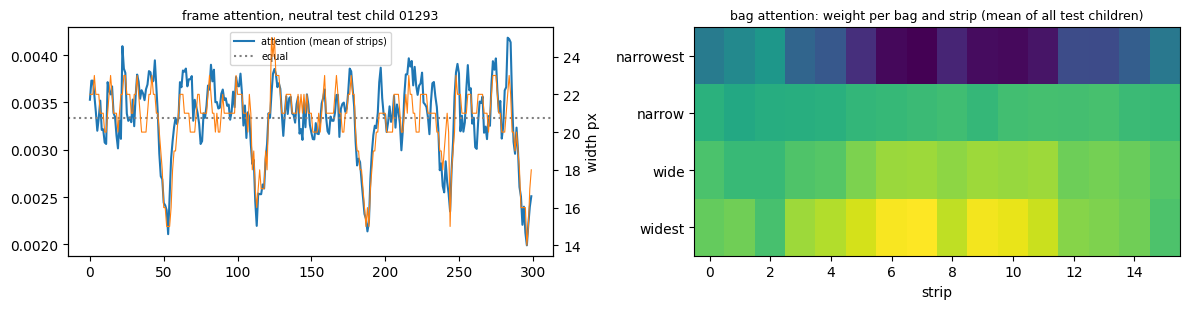

In [8]:
_, _, raw_f = mini['frame attention']
eff = np.array([(1 / (r['alpha'] ** 2).sum(0)).mean() for r in raw_f])      # alpha [300, 16]
print('frame attention: effective number of frames, mean', eff.mean().round(1), '| min', eff.min().round(1),
      '| max', eff.max().round(1), '(of 300)')

y_test = np.array([it['label'] for it in mini_test])
w_test = np.array([box_size(it['seq'][:300])[0] for it in mini_test])
rho = [spearmanr(r['alpha'].mean(1), w)[0] for r, w in zip(raw_f, w_test)]
print('Spearman(frame weight, silhouette width): mean', np.round(np.mean(rho), 2))

_, _, raw_b = mini['bag attention']
bag_w = np.array([r['alpha'].mean(1) for r in raw_b])                         # [children, 4]
print()
print('bag attention: mean weight per width quarter (equal = 0.25)')
for c in range(3):
    print(f'  true {LABEL_NAMES[c]:8s} | ' + '  '.join(f'{v:.2f}' for v in bag_w[y_test == c].mean(0)))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
i = int(np.where(y_test == 1)[0][0])
ax[0].plot(raw_f[i]['alpha'].mean(1), label='attention (mean of strips)')
ax[0].axhline(1 / 300, color='gray', ls=':', label='equal')
a2 = ax[0].twinx()
a2.plot(w_test[i], color='tab:orange', lw=0.8)
a2.set_ylabel('width px')
ax[0].set_title(f'frame attention, neutral test child {mini_test[i]["subject"]}', fontsize=9)
ax[0].legend(fontsize=7)
ax[1].imshow(np.array([r['alpha'] for r in raw_b]).mean(0), cmap='viridis', aspect='auto')
ax[1].set_yticks(range(4), ['narrowest', 'narrow', 'wide', 'widest'])
ax[1].set_xlabel('strip')
ax[1].set_title('bag attention: weight per bag and strip (mean of all test children)', fontsize=9)
save_and_show(fig, '06_attention.png')

**frame attention stays close to equal weights, effective number of frames 288 of 300**, so it's almost a mean pooling. but it's not random: the weight follows the silhouette width very closely (**Spearman 0.69**). in the picture the attention (blue) drops at every turn (width dips to ~14-16 px) to about 0.002, and it's ~0.0035 in the wide frames. so it learned **"trust the turning / side frames less"** by itself, without being told what a view is.

**bag attention learned the same thing**: the narrowest bag gets less weight (0.23) and the widest the most (0.26). in the heatmap the effect is strongest in the **middle strips (about 5-11, the trunk)**, where the narrowest bag clearly gets the least, while at the head and feet the 4 bags are closer to equal. **the attention is the same for all 3 classes** (0.23 / 0.25 / 0.26 / 0.26 for negative, neutral and positive), so it learned a general view preference ("trunk from the front or back"), not a class-specific one. this fits the clinic: scoliosis is seen in the trunk from the back (shoulder and hip asymmetry), and that's hard to see from the side.

step 7: analysis

**1. does the order of the frames matter for ScoNet-MT?**

not at all (difference 0.0). it can't see motion over time, only a set of postures, so any "gait" information it uses has to be visible in single frames.

**2. which frames does the max listen to?**

about 3x more to some frames than an even spread (the top 10% of frames win 28% of the cells), mostly the extreme ones: the widest (front / back) and the narrowest (side, turning). that's the same for all classes, so the max doesn't "look for" scoliosis frames, it just collects extremes, including the less useful side views.

**3. what did the learned attention find?**

on its own it learned to give the turning / side frames less weight (Spearman 0.69 with width), and the bag attention did the same, mostly for the trunk strips. that's a sensible, clinically plausible view preference. but the effect is mild (the weights only vary by ~2x), and it gives no clear gain in this mini setting (67.5 vs 65.8).

**4. are view bags (the TG-MILNet idea) better than attention over single frames?**

not here: 64.2 vs 67.5, and both learned the same preference. frame attention is simpler (no bag rule) and found the views by itself.

**5. what would make temporal modelling matter more?**

something that can see *motion*, because ScoNet-MT, max, attention and bags are all order-free. a model that compares neighbouring frames (temporal convolution, like the 3D CNN of ScoliGaitX / GaitGL, or GEI-subtract which removes the static shape) is the next thing to test. and with 16-frame clips in training, the full 300-frame sequence is never seen at once.

**6. what are the limitations?**

- part A uses one full model (official@16k) and 60 test children.
- the width is a rough stand-in for the view (a child with the arms close to the body is also narrow).
- the mini training is 1 seed, 500 iterations, 120 training children (balanced) and a clip test (10 x 16 frames). the 3 heads differ by 1-2 children, which is noise.
- my bags are width quarters, not TG-MILNet's DTW clusters (notebook 06), and there is no IBTA.
- the attention is per strip but shared between the classes, so a per-class attention could find something different.

what can we absorb into the new architecture?

**frame attention (gated attention MIL, per strip) is a reasonable replacement for max pooling**: it's cheap (131k parameters), it starts as a mean, and it learned an interpretable view preference by itself. that's useful for the paper as an explainability figure ("the model trusts front / back trunk frames"), even if the accuracy gain is small. and i **shouldn't build complicated bags first**, because in my test the hand-made view bags were not better than frame attention, which found the views on its own.

**the bigger missing piece is motion**, because all the tested poolings are order-free. if we want a real temporal model, i should test something that sees neighbouring frames (a temporal 1D conv over frame features, or a 3D-conv block), as an ablation against order-free pooling. and **train and test with the same kind of input**: the 300-frame vs 16-frame mismatch (notebook 01, question 6) is a temporal issue too, so for the full model i should check if training with more frames or testing with clips changes the results.